# Extra: datos reales de EODHD

Hasta ahora los agentes solo han visto mercados simulados. Aquí probamos los mismos agentes con precios reales.

Los entrenamientos se lanzan con `python scripts/datos_reales.py` y los resultados se guardan en `results/reales_*.csv`. Este notebook los lee. Las figuras que dibujan precios necesitan además los datos en `data/`: cada uno los descarga una vez con su propia clave de EODHD, guardada en `.env`.

**Activos.** Precios diarios ajustados de:

- **S&P 500 (a través del fondo SPY):** incluye dividendos.
- **IBEX 35:** solo el precio del índice, sin dividendos.
- **Bitcoin:** cotiza todos los días, también los fines de semana.
- **EUR/USD:** el tipo de cambio del euro frente al dólar.

**Periodos.**

- **Entrenamiento:** de 2005 a 2018 (Bitcoin, desde 2014, porque antes apenas se negociaba). Cada episodio es una ventana de 500 días elegida al azar dentro de ese periodo.
- **Test:** desde 2019 hasta el último dato, recorrido de una vez como un único episodio que empieza sin el activo.

**Aquí no se ajustan hiperparámetros.** De cada activo solo hay una historia, y elegir la configuración mirándola sería hacer trampa (sobreajuste). En su lugar se prueban dos configuraciones decididas de antemano, con Q-learning y Sarsa y 10 semillas cada una:

- **sin ajustar:** la de la fase 1;
- **regímenes:** la que salió mejor en la fase 2 para el mercado de regímenes, que es el simulado que más se parece a un mercado real.

**Una limitación importante.** De cada activo hay un único periodo de test. Las 10 semillas miden cuánto cambia el resultado según el azar del entrenamiento, no según el mercado, así que aquí no hay intervalos de confianza como en la fase 3.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rl_trader
from rl_trader.evaluation import ejecutar_episodio
from rl_trader.plots import AZUL, EJE, FONDO, GRIS, NARANJA, SECUENCIAL, TINTA_2, aplicar_estilo, corto, formato_log
from rl_trader.real import FIN_ENTRENAMIENTO, INICIO_TEST, cargar, dividir, politica_desde_cadena

aplicar_estilo()
ROOT = Path(rl_trader.__file__).resolve().parent.parent
RESULTADOS, FIGURAS = ROOT / "results", ROOT / "figures"

periodos = pd.read_csv(RESULTADOS / "reales_periodos.csv")
resultados = pd.read_csv(RESULTADOS / "reales_resultados.csv")
politicas = pd.read_csv(RESULTADOS / "reales_politicas.csv", dtype={"politica": str})
resultados["variante"] = resultados["variante"].fillna("")
politicas["variante"] = politicas["variante"].fillna("")

ACTIVOS = list(periodos["activo"])
NOMBRES = dict(zip(periodos["activo"], periodos["nombre"]))
AGENTES = [("aleatorio", ""), ("buy_and_hold", ""), ("momentum", ""), ("contrarian", ""),
           ("qlearning", "sin ajustar"), ("sarsa", "sin ajustar"), ("qlearning", "regímenes"), ("sarsa", "regímenes")]
ETIQUETAS = {("aleatorio", ""): "Aleatorio", ("buy_and_hold", ""): "Buy & hold", ("momentum", ""): "Momentum",
             ("contrarian", ""): "Contrarian", ("qlearning", "sin ajustar"): "Q-learning sin ajustar",
             ("sarsa", "sin ajustar"): "Sarsa sin ajustar", ("qlearning", "regímenes"): "Q-learning (regímenes)",
             ("sarsa", "regímenes"): "Sarsa (regímenes)"}
precios = {a: cargar(a) for a in ACTIVOS}
periodos

,activo,ticker,nombre,inicio_entrenamiento,fin_entrenamiento,dias_entrenamiento,inicio_test,fin_test,dias_test
0,sp500,SPY.US,S&P 500 (SPY),2005-01-03,2018-12-31,3523,2019-01-02,2026-10-26,1965
1,ibex,IBEX.INDX,IBEX 35,2005-01-03,2018-12-31,3571,2019-01-02,2026-10-27,2010
2,bitcoin,BTC-USD.CC,Bitcoin,2014-01-01,2018-12-31,1826,2019-01-01,2026-10-27,2857
3,eurusd,EURUSD.FOREX,EUR/USD,2005-01-03,2018-12-31,3651,2019-01-01,2026-10-26,2151


## 1. Los activos

Cómo ha evolucionado el precio de cada activo, partiendo de 1 al principio y en escala logarítmica. La zona sombreada es el periodo de test.

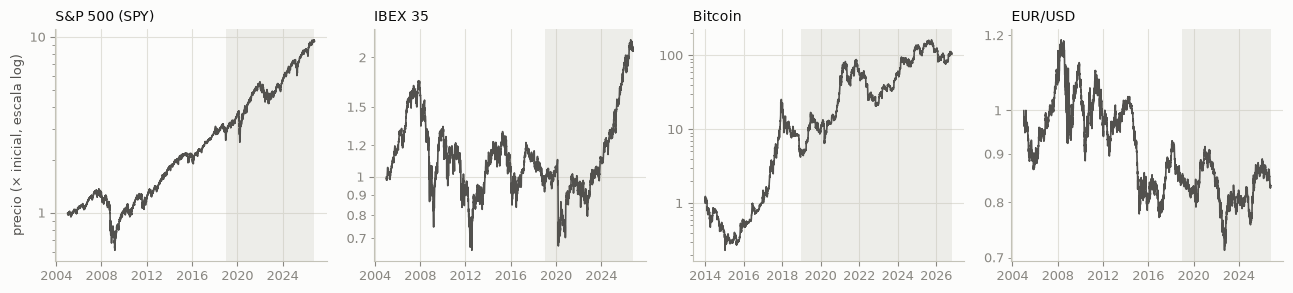

       activo       periodo  rentabilidad anual %  volatilidad anual %
S&P 500 (SPY) entrenamiento                   7.5                 18.7
S&P 500 (SPY)          test                  17.1                 19.2
      IBEX 35 entrenamiento                  -0.5                 23.0
      IBEX 35          test                  10.6                 18.9
      Bitcoin entrenamiento                  37.1                 75.5
      Bitcoin          test                  47.3                 60.4
      EUR/USD entrenamiento                  -1.1                 12.6
      EUR/USD          test                  -0.3                  6.8


In [2]:
fig, axes = plt.subplots(1, len(ACTIVOS), figsize=(13, 3), squeeze=False)
for ax, a in zip(axes[0], ACTIVOS):
    s = precios[a] / precios[a].iloc[0]
    ax.axvspan(pd.Timestamp(INICIO_TEST), s.index[-1], color=EJE, alpha=0.25, lw=0)
    ax.plot(s.index, s.values, color=TINTA_2, lw=1.2)
    ax.set_yscale("log")
    formato_log(ax.yaxis)
    ax.set_title(NOMBRES[a], loc="left")
axes[0][0].set_ylabel("precio (× inicial, escala log)")
fig.tight_layout()
fig.savefig(FIGURAS / "reales_activos.png", dpi=200)
plt.show()

# Rentabilidad anual y volatilidad anualizada de cada periodo (días de mercado por año: 365 en Bitcoin, 252 en el resto)
filas = []
for a in ACTIVOS:
    dias = 365 if a == "bitcoin" else 252
    for nombre, tramo in (("entrenamiento", precios[a][:FIN_ENTRENAMIENTO]), ("test", precios[a][INICIO_TEST:])):
        r = tramo.pct_change().dropna()
        filas.append({"activo": NOMBRES[a], "periodo": nombre,
                      "rentabilidad anual %": 100 * ((tramo.iloc[-1] / tramo.iloc[0]) ** (dias / len(r)) - 1),
                      "volatilidad anual %": 100 * r.std() * np.sqrt(dias)})
print(pd.DataFrame(filas).to_string(index=False, float_format=lambda v: f"{v:.1f}"))

## 2. Resultados en test (desde 2019)

Para los agentes de RL y el aleatorio se da la mediana de las 10 semillas. `retorno_test_%` es la rentabilidad en test y `rango_semillas`, entre qué valores se mueve según la semilla. `retorno_entrenamiento_%` es la rentabilidad que obtiene el agente si recorre de una vez todo el periodo de entrenamiento: si es mucho mejor que la de test, el agente ha aprendido patrones que después no se repiten.

In [3]:
def resumen(d, periodo):
    t = d[d.periodo == periodo]
    return t["retorno_pct"].median(), t


filas = []
for a in ACTIVOS:
    for agente, variante in AGENTES:
        d = resultados[(resultados.activo == a) & (resultados.agente == agente) & (resultados.variante == variante)]
        ret_test, t = resumen(d, "test")
        ret_entr, _ = resumen(d, "entrenamiento")
        filas.append({"activo": NOMBRES[a], "agente": ETIQUETAS[(agente, variante)],
                      "retorno_test_%": ret_test, "sharpe": t["sharpe"].median(),
                      "drawdown_%": t["max_drawdown_pct"].median(), "operaciones": t["operaciones"].median(),
                      "dentro_%": t["tiempo_dentro_pct"].median(),
                      "rango_semillas": f"{corto(t['retorno_pct'].min())} a {corto(t['retorno_pct'].max())}" if len(t) > 1 else "",
                      "retorno_entrenamiento_%": ret_entr})
tabla = pd.DataFrame(filas)
tabla.to_csv(RESULTADOS / "reales_tabla.csv", index=False)
with pd.option_context("display.width", 250):
    print(tabla.to_string(index=False, float_format=corto))

       activo                 agente  retorno_test_%  sharpe  drawdown_%  operaciones  dentro_% rango_semillas  retorno_entrenamiento_%
S&P 500 (SPY)              Aleatorio            -8.1    -0.0        32.3          650      51.0    -37.5 a 4.0                    -48.3
S&P 500 (SPY)             Buy & hold             232     0.9        33.7          1.0       100                                     178
S&P 500 (SPY)               Momentum             1.1     0.1        30.8          452      61.9                                   -69.9
S&P 500 (SPY)             Contrarian            33.3     0.3        29.6          451      38.1                                    65.2
S&P 500 (SPY) Q-learning sin ajustar            43.6     0.4        29.6          243      34.0    29.3 a 43.6                      143
S&P 500 (SPY)      Sarsa sin ajustar            31.4     0.3        27.7          250      27.0    30.7 a 48.0                     99.2
S&P 500 (SPY) Q-learning (regímenes)            

## 3. Capital en el periodo de test

Cómo evoluciona, día a día, el capital de cada agente de RL (con la configuración de regímenes). La línea es la mediana de las 10 semillas y la banda va de la peor a la mejor semilla. Las curvas se obtienen volviendo a aplicar las políticas guardadas sobre los precios descargados en `data/`.

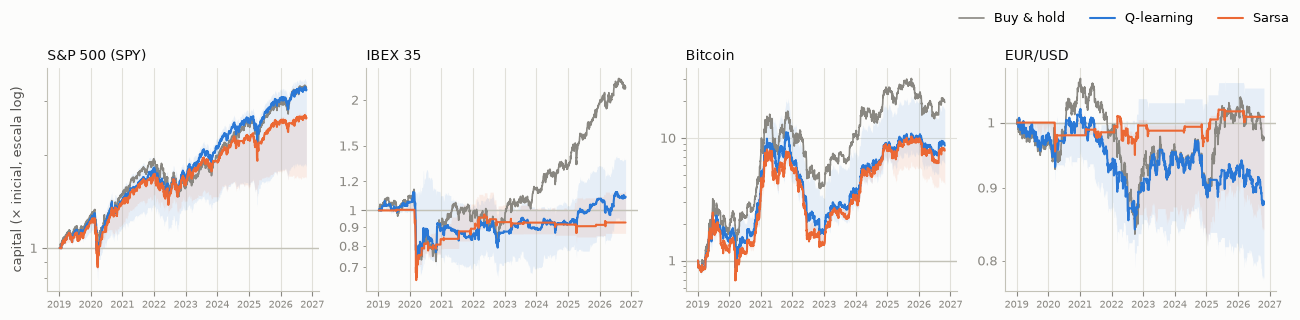

In [4]:
def curvas(a, agente, variante):
    _, test = dividir(precios[a])
    p = politicas[(politicas.activo == a) & (politicas.agente == agente) & (politicas.variante == variante)]
    return np.array([ejecutar_episodio(test, politica_desde_cadena(f.politica, json.loads(f.cortes)))[0] / 1000
                     for f in p.itertuples()])


fig, axes = plt.subplots(1, len(ACTIVOS), figsize=(13, 3.2), squeeze=False)
for ax, a in zip(axes[0], ACTIVOS):
    _, test = dividir(precios[a])
    fechas = precios[a][INICIO_TEST:].index[5:]
    bh = ejecutar_episodio(test, lambda obs: 2)[0] / 1000
    ax.axhline(1, color=EJE, lw=1)
    ax.plot(fechas, bh, color=GRIS, lw=1.2, label="Buy & hold")
    for (agente, color, etiqueta) in (("qlearning", AZUL, "Q-learning"), ("sarsa", NARANJA, "Sarsa")):
        c = curvas(a, agente, "regímenes")
        ax.fill_between(fechas, c.min(axis=0), c.max(axis=0), color=color, alpha=0.1, lw=0)
        ax.plot(fechas, np.median(c, axis=0), color=color, lw=1.5, label=etiqueta)
    ax.set_yscale("log")
    formato_log(ax.yaxis)
    ax.set_title(NOMBRES[a], loc="left")
    ax.tick_params(axis="x", labelrotation=0)
    for etiqueta in ax.get_xticklabels():
        etiqueta.set_fontsize(7)
axes[0][0].set_ylabel("capital (× inicial, escala log)")
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="upper right", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(FIGURAS / "reales_capital_test.png", dpi=200)
plt.show()

## 4. Políticas aprendidas (configuración de regímenes)

Como en la fase 3: para cada estado, qué fracción de las 10 semillas está **dentro** del mercado. En el eje vertical están los cortes de la tendencia, que son distintos para cada activo.

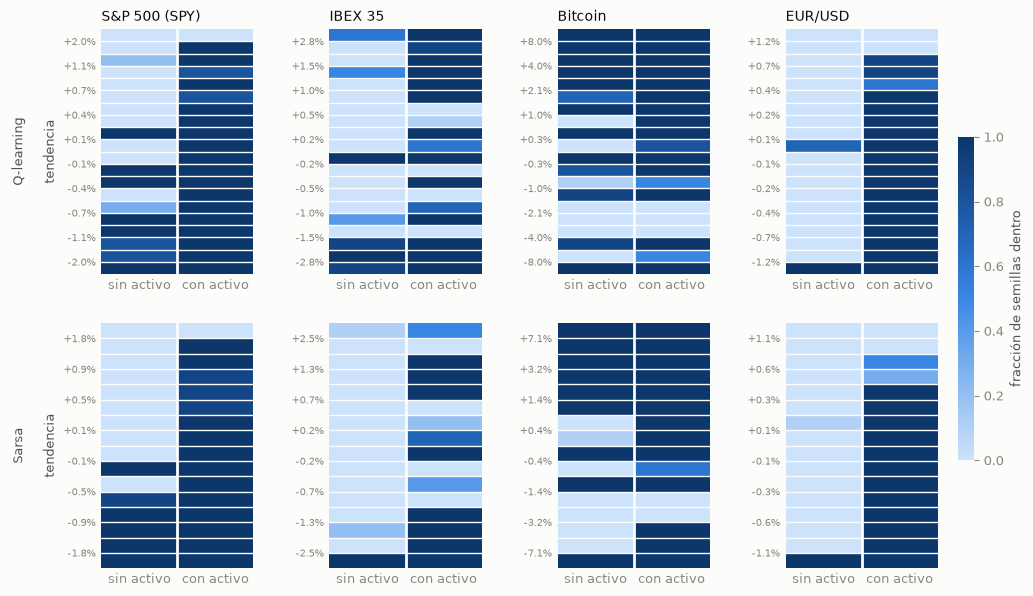

In [5]:
def efectiva(cadena):
    v = np.array(list(cadena), dtype=int)
    if not v[0::2].any():
        v[1::2] = 0
    return v


fig, axes = plt.subplots(2, len(ACTIVOS), figsize=(13, 7), squeeze=False, gridspec_kw={"wspace": 0.5})
for i, (agente, etiqueta) in enumerate((("qlearning", "Q-learning"), ("sarsa", "Sarsa"))):
    for j, a in enumerate(ACTIVOS):
        p = politicas[(politicas.activo == a) & (politicas.agente == agente) & (politicas.variante == "regímenes")]
        cortes = json.loads(p["cortes"].iloc[0])
        n = len(cortes) + 1
        dentro = np.mean([efectiva(c) for c in p["politica"]], axis=0).reshape(n, 2)
        ax = axes[i, j]
        im = ax.imshow(dentro, cmap=SECUENCIAL, vmin=0, vmax=1, aspect="auto", origin="lower")
        paso = 1 if n <= 10 else 2
        posiciones = np.arange(1, n)[::-1][::paso][::-1]
        ax.set_yticks(posiciones - 0.5, [f"{100 * cortes[k - 1]:+.1f}%" for k in posiciones], fontsize=7)
        ax.set_xticks([0, 1], ["sin activo", "con activo"])
        ax.tick_params(length=0)
        ax.grid(False)
        for lado in ax.spines.values():
            lado.set_visible(False)
        for k in range(1, n):
            ax.axhline(k - 0.5, color=FONDO, lw=1)
        ax.axvline(0.5, color=FONDO, lw=2)
        if i == 0:
            ax.set_title(NOMBRES[a], loc="left")
    axes[i, 0].set_ylabel(f"{etiqueta}\n\ntendencia")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label("fracción de semillas dentro", color=TINTA_2)
cb.outline.set_visible(False)
fig.savefig(FIGURAS / "reales_politicas.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Conclusiones

Rentabilidades del periodo de test completo (de 2019 a octubre de 2026). Para los agentes de RL se da la mediana de 10 semillas.

**Con datos reales, ningún agente gana con claridad a buy & hold, y el motivo es que se sobreajustan a una única historia.** En el periodo de entrenamiento (2005–2018), los agentes con la configuración de regímenes ganan a buy & hold en los cuatro activos, a menudo por mucho; los sin ajustar, en tres de los cuatro (no en el S&P 500). En test, en cambio, se quedan por debajo o, como mucho, a su altura.

| Activo | Buy & hold (test) | Mejor agente (test) | Agentes en entrenamiento | Buy & hold en entrenamiento |
|---|---|---|---|---|
| S&P 500 | +232% | Q-learning (regímenes) +228% | +99% a +338% | +178% |
| IBEX 35 | +117% | Q-learning (regímenes) +9% | +75% a +124% | −5% |
| Bitcoin | +1.850% | Q-learning (regímenes) +767% | +1.303% a +2.851% | +292% |
| EUR/USD | −2,8% | Sarsa (regímenes) +0,9% | +34% a +44% | −13% |

**Activo por activo:**

- **S&P 500:** el único caso en que un agente iguala a buy & hold. Q-learning con la configuración de regímenes consigue +228% frente a +232%, con algo más de Sharpe (1,0 frente a 0,9) y algo menos de drawdown (32% frente a 34%). Aprende a **comprar en las caídas y mantener casi siempre** (está dentro el 87% del tiempo): una regla que funcionó entre 2005 y 2018 y siguió funcionando después. La configuración sin ajustar se queda en +31–44%, porque opera demasiado.
- **IBEX 35:** el ejemplo más claro de sobreajuste. Entre 2005 y 2018 el índice bajó (−5% con buy & hold), y los agentes aprendieron a estar fuera casi siempre y a entrar sobre todo tras caídas fuertes; así ganaban entre un 75% y un 124%. Entre 2019 y 2026 el índice subió un 117%, y esas mismas políticas se quedaron entre el −7% y el +9%. A Sarsa con la configuración de regímenes le salió caro entrar en la caída de marzo de 2020.
- **Bitcoin:** los agentes (+480% a +767%) ganan a las reglas fijas (momentum, +281%), pero quedan muy lejos de buy & hold (+1.850%). Además, con la configuración de regímenes sufren caídas máximas peores que buy & hold (84–85% frente a 77%): salen y entran en malos momentos.
- **EUR/USD:** no hay nada que aprovechar. Buy & hold pierde un 2,8% y las reglas fijas, un 40% en comisiones. Sarsa con la configuración de regímenes casi no opera (está dentro el 10% del tiempo) y queda en +0,9%. Q-learning opera más y pierde (del −12% al −15%).

**Qué aprendemos.**

- **Los mercados reales no son estacionarios: cambian con el tiempo.** En los mercados simulados, el entrenamiento y el test salían del mismo generador. Aquí, lo que pasó con cada activo entre 2005 y 2018 no se repite entre 2019 y 2026, y una tabla Q aprendida con una sola historia acaba memorizando esa historia.
- **La configuración ajustada en simulación sí ayuda algo.** La de regímenes (α fijo y pequeño, γ alto) gana a la sin ajustar en el S&P 500 y en Bitcoin. Cuando no se puede validar con datos reales, usar los hiperparámetros de un mercado simulado parecido parece razonable.
- **El agente ve demasiado poco.** Con solo la tendencia de los últimos 6 días y su posición, no puede saber en qué tipo de mercado está ni adaptarse a cambios a largo plazo.
- **Un solo periodo de test no permite sacar conclusiones firmes.** No hay intervalos de confianza: las 10 semillas solo miden cuánto cambia el resultado según el entrenamiento.

**Qué haría falta para mejorar:** validar con ventanas que avanzan en el tiempo (*walk-forward*), entrenar con varios activos a la vez para no memorizar una sola historia, y darle al agente más información (volatilidad, tendencias más largas).